# Result Quality Analysis

This notebook compares the actual query results from each model against the expected results.

**Evaluation metrics:**
- Row count accuracy
- Column similarity (Jaccard)
- Row content precision, recall, and F1
- Overall quality score

Only queries with `executionSuccess = true` are analyzed.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from typing import Dict, List, Any, Tuple
from collections import Counter
import Levenshtein

# Set style (same as notebook 1)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Color palette (same as notebook 1)
MODEL_COLORS = {
    'ollama-duckdb-nsql': '#2E86AB',
    'ollama-llama2': '#A23B72',
    'ollama-phi3': '#F18F01',
    'openrouter-gemini-2.5-flash': '#C73E1D',
    'openrouter-gpt-5-mini': '#6A994E',
    'openrouter-gpt-oss-120b': '#BC4B51',
    'openrouter-qwen3-32b': '#8B5A3C'
}

# Paths
BASE_PATH = Path('../..')
RESULTS_PATH = BASE_PATH / 'backend' / 'logs' / 'batch-results'
TEST_SUITE_PATH = BASE_PATH / 'backend' / 'tests' / 'test-suite.json'
FIGS_PATH = BASE_PATH / 'analysis' / 'figs'
TABLES_PATH = BASE_PATH / 'analysis' / 'tables'

print("✓ Libraries imported and paths configured")

✓ Libraries imported and paths configured


## 1. Load Data and Expected Results

In [2]:
# Load test suite
with open(TEST_SUITE_PATH, 'r', encoding='utf-8') as f:
    test_suite = json.load(f)

# Create expected results mapping
expected_results = {}
complexity_map = {}

for q in test_suite['questions']:
    expected_results[q['id']] = q['expectedResults']
    complexity_map[q['id']] = q['complexity']

print(f"✓ Loaded expected results for {len(expected_results)} queries")

# Load all model results
def load_model_results(model_name):
    model_path = RESULTS_PATH / model_name
    results = []
    
    for i in range(1, 21):
        query_file = model_path / f'query-{i}.json'
        if query_file.exists():
            with open(query_file, 'r', encoding='utf-8') as f:
                data = json.load(f)
                results.append(data)
    
    return results

models = list(MODEL_COLORS.keys())
all_results = {}

for model in models:
    all_results[model] = load_model_results(model)
    print(f"✓ Loaded {len(all_results[model])} queries for {model}")

✓ Loaded expected results for 20 queries
✓ Loaded 20 queries for ollama-duckdb-nsql
✓ Loaded 20 queries for ollama-duckdb-nsql
✓ Loaded 20 queries for ollama-llama2
✓ Loaded 20 queries for ollama-llama2
✓ Loaded 20 queries for ollama-phi3
✓ Loaded 20 queries for ollama-phi3
✓ Loaded 20 queries for openrouter-gemini-2.5-flash
✓ Loaded 20 queries for openrouter-gpt-5-mini
✓ Loaded 20 queries for openrouter-gemini-2.5-flash
✓ Loaded 20 queries for openrouter-gpt-5-mini
✓ Loaded 20 queries for openrouter-gpt-oss-120b
✓ Loaded 20 queries for openrouter-qwen3-32b
✓ Loaded 20 queries for openrouter-gpt-oss-120b
✓ Loaded 20 queries for openrouter-qwen3-32b


## 2. Comparison Functions

In [ ]:
# datetime
from datetime import datetime

def normalize_string(s):
    if s is None:
        return None
    s = str(s).strip().lower()
    # manter underscores, hifens e espaços
    return s.replace('"', '').replace("'", '')

def normalize_value(val):
    if val is None:
        return None

    # tenta converter número
    if isinstance(val, str):
        try:
            num = float(val)
            return round(num, 2)
        except:
            pass  # não é número

    if isinstance(val, (int, float)):
        return round(float(val), 2)

    # datas?
    try:
        dt = datetime.fromisoformat(val)
        return dt.date().isoformat()
    except:
        pass

    return normalize_string(val)

import re

def tokenize(col: str):
    if col is None:
        return []
    s = str(col).strip().lower().replace('"', '').replace("'", '')
    # separa por underscores, hifens, barras, espaços e camelCase
    s = re.sub(r'([a-z])([A-Z])', r'\1 \2', s)
    s = re.sub(r'[_\-/\.]', ' ', s)
    return [t for t in s.split() if t]


def token_overlap_score(c1: str, c2: str) -> float:
    t1 = set(tokenize(c1))
    t2 = set(tokenize(c2))
    if not t1 or not t2:
        return 0.0
    return len(t1 & t2) / len(t1 | t2)

def calculate_column_similarity(cols_model, cols_expected):
    norm_model = {normalize_string(c): c for c in cols_model}
    norm_expected = {normalize_string(c): c for c in cols_expected}
    
    intersection = set(norm_model.keys()) & set(norm_expected.keys())
    union = set(norm_model.keys()) | set(norm_expected.keys())
    
    unmatched_model = set(norm_model.keys()) - intersection
    unmatched_expected = set(norm_expected.keys()) - intersection
    
    column_mapping = {}
    
    # fuzzy + token-based matching
    for cm in list(unmatched_model):
        best_match = None
        best_score = 0
        for ce in unmatched_expected:
            if not cm or not ce:
                continue
            
            # duas componentes: texto e tokens
            lev = Levenshtein.ratio(cm, ce)
            tok = token_overlap_score(norm_model[cm], norm_expected[ce])
            
            score = max(lev, tok)  # ou alguma combinação
            
            if score > 0.5 and score > best_score:
                best_match = ce
                best_score = score
        
        if best_match:
            intersection.add(cm)
            column_mapping[norm_model[cm]] = norm_expected[best_match]
            unmatched_model.remove(cm)
            unmatched_expected.remove(best_match)
    
    for col in intersection:
        if col in norm_model and col in norm_expected:
            column_mapping[norm_model[col]] = norm_expected[col]
    
    jaccard = len(intersection) / len(union) if union else 0.0
    return jaccard, column_mapping

def compare_rows(rows_model: List[Dict], rows_expected: List[Dict], column_mapping: Dict) -> Dict:
    if not column_mapping:
        return {
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0
        }
    
    # ordem canônica: nomes das colunas ESPERADAS, ordenados
    expected_cols = sorted(column_mapping.values())
    # mapping invertido: expected_col -> model_col
    inverse_mapping = {v: k for k, v in column_mapping.items()}
    
    # normaliza linhas do modelo usando SEMPRE a ordem das expected_cols
    model_multiset = Counter([
        tuple(
            normalize_value(row.get(inverse_mapping[col]))
            for col in expected_cols
        )
        for row in rows_model
    ])
    
    # normaliza linhas esperadas na MESMA ordem
    expected_multiset = Counter([
        tuple(
            normalize_value(row.get(col))
            for col in expected_cols
        )
        for row in rows_expected
    ])
    
    matches = sum((model_multiset & expected_multiset).values())
    total_model = sum(model_multiset.values())
    total_expected = sum(expected_multiset.values())
    
    precision = matches / total_model if total_model > 0 else 0.0
    recall = matches / total_expected if total_expected > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        'precision': precision,
        'recall': recall,
        'f1': f1
    }


def evaluate_query_results(model_result: Dict, expected: Dict) -> Dict:
    """Evaluate a single query result."""
    notes = []
    
    # Skip if execution failed
    if not model_result.get('executionSuccess', False):
        return {
            'row_count_score': 0.0,
            'column_score': 0.0,
            'row_precision': 0.0,
            'row_recall': 0.0,
            'row_f1': 0.0,
            'overall_score': 0.0,
            'notes': ['Execution failed']
        }
    
    model_results = model_result.get('results', {})
    
    # Row count
    row_count_model = model_results.get('rowCount', 0)
    row_count_expected = expected.get('rowCount', 0)
    row_count_score = 1.0 if row_count_model == row_count_expected else 0.0
    
    if row_count_model != row_count_expected:
        notes.append(f'rowCount differs ({row_count_model} vs {row_count_expected})')
    
    # Columns
    cols_model = model_results.get('columns', [])
    cols_expected = expected.get('columns', [])
    column_score, column_mapping = calculate_column_similarity(cols_model, cols_expected)
    
    if column_score < 1.0:
        notes.append(f'Column mismatch (similarity: {column_score:.2f})')
    
    # Rows
    rows_model = model_results.get('rows', [])
    rows_expected = expected.get('rows', [])
    row_metrics = compare_rows(rows_model, rows_expected, column_mapping)
    
    # Overall score
    overall_score = (
        0.5 * row_count_score +
        0.2 * column_score +
        0.3 * row_metrics['f1']
    )
    
    return {
        'row_count_score': row_count_score,
        'column_score': column_score,
        'row_precision': row_metrics['precision'],
        'row_recall': row_metrics['recall'],
        'row_f1': row_metrics['f1'],
        'overall_score': overall_score,
        'notes': notes
    }

print("✓ Comparison functions defined")

✓ Comparison functions defined


## 3. Evaluate All Results

In [31]:
# Evaluate all queries for all models
evaluation_results = []

for model, queries in all_results.items():
    print(f"\nEvaluating {model}...")
    for query in queries:
        question_id = query['questionId']
        expected = expected_results.get(question_id, {})
        
        eval_result = evaluate_query_results(query, expected)
        
        evaluation_results.append({
            'model': model,
            'questionId': question_id,
            'complexity': complexity_map.get(question_id, 'unknown'),
            **eval_result
        })
    print(f"  ✓ Evaluated {len(queries)} queries")

eval_df = pd.DataFrame(evaluation_results)
print(f"\n✓ Created evaluation DataFrame with {len(eval_df)} rows")
eval_df.head(10)


Evaluating ollama-duckdb-nsql...
  ✓ Evaluated 20 queries

Evaluating ollama-llama2...
  ✓ Evaluated 20 queries

Evaluating ollama-phi3...
  ✓ Evaluated 20 queries

Evaluating openrouter-gemini-2.5-flash...
  ✓ Evaluated 20 queries

Evaluating openrouter-gpt-5-mini...
  ✓ Evaluated 20 queries

Evaluating openrouter-gpt-oss-120b...
  ✓ Evaluated 20 queries

Evaluating openrouter-qwen3-32b...
  ✓ Evaluated 20 queries

✓ Created evaluation DataFrame with 140 rows
  ✓ Evaluated 20 queries

Evaluating openrouter-gpt-oss-120b...
  ✓ Evaluated 20 queries

Evaluating openrouter-qwen3-32b...
  ✓ Evaluated 20 queries

✓ Created evaluation DataFrame with 140 rows


,model,questionId,complexity,row_count_score,column_score,row_precision,row_recall,row_f1,overall_score,notes
0,ollama-duckdb-nsql,1,simple,1.0,1.00,1.0,1.0,1.0,1.00,[]
1,ollama-duckdb-nsql,2,simple,1.0,1.00,1.0,1.0,1.0,1.00,[]
2,ollama-duckdb-nsql,3,simple,1.0,0.75,1.0,1.0,1.0,0.95,[Column mismatch (similarity: 0.75)]
3,ollama-duckdb-nsql,4,simple,1.0,1.00,1.0,1.0,1.0,1.00,[]
4,ollama-duckdb-nsql,5,simple,1.0,1.00,1.0,1.0,1.0,1.00,[]
5,ollama-duckdb-nsql,6,moderate,0.0,0.00,0.0,0.0,0.0,0.00,"[rowCount differs (0 vs 6), Column mismatch (s..."
6,ollama-duckdb-nsql,7,moderate,0.0,0.00,0.0,0.0,0.0,0.00,[Execution failed]
7,ollama-duckdb-nsql,8,moderate,1.0,0.50,1.0,1.0,1.0,0.90,[Column mismatch (similarity: 0.50)]
8,ollama-duckdb-nsql,9,moderate,1.0,1.00,1.0,1.0,1.0,1.00,[]
9,ollama-duckdb-nsql,10,moderate,1.0,0.25,1.0,1.0,1.0,0.85,[Column mismatch (similarity: 0.25)]


## 4. Overall Quality Statistics

In [32]:
# Calculate overall statistics by model
quality_stats = eval_df.groupby('model').agg({
    'row_count_score': 'mean',
    'column_score': 'mean',
    'row_precision': 'mean',
    'row_recall': 'mean',
    'row_f1': 'mean',
    'overall_score': 'mean'
}).round(4)

quality_stats.columns = [
    'Row Count Accuracy',
    'Column Similarity',
    'Row Precision',
    'Row Recall',
    'Row F1',
    'Overall Score'
]

# Add % of queries with correct row count
quality_stats['% Correct Row Count'] = eval_df.groupby('model')['row_count_score'].apply(
    lambda x: (x == 1.0).sum() / len(x) * 100
).round(2)

quality_stats.to_csv(TABLES_PATH / 'result_quality_stats.csv')
print("✓ Saved quality statistics table")

quality_stats

✓ Saved quality statistics table


,Row Count Accuracy,Column Similarity,Row Precision,Row Recall,Row F1,Overall Score,% Correct Row Count
model,,,,,,,
ollama-duckdb-nsql,0.60,0.5167,0.5411,0.5411,0.5411,0.5656,60.0
ollama-llama2,0.10,0.2042,0.1829,0.2440,0.1865,0.1468,10.0
ollama-phi3,0.20,0.1383,0.2000,0.2000,0.2000,0.1877,20.0
openrouter-gemini-2.5-flash,0.90,0.7025,0.6884,0.6825,0.6853,0.7961,90.0
openrouter-gpt-5-mini,0.90,0.7170,0.7094,0.7038,0.7064,0.8053,90.0
openrouter-gpt-oss-120b,0.90,0.7767,0.7941,0.7885,0.7911,0.8427,90.0
openrouter-qwen3-32b,0.95,0.6892,0.7394,0.7338,0.7364,0.8338,95.0


## 5. Visualizations: Overall Quality Metrics

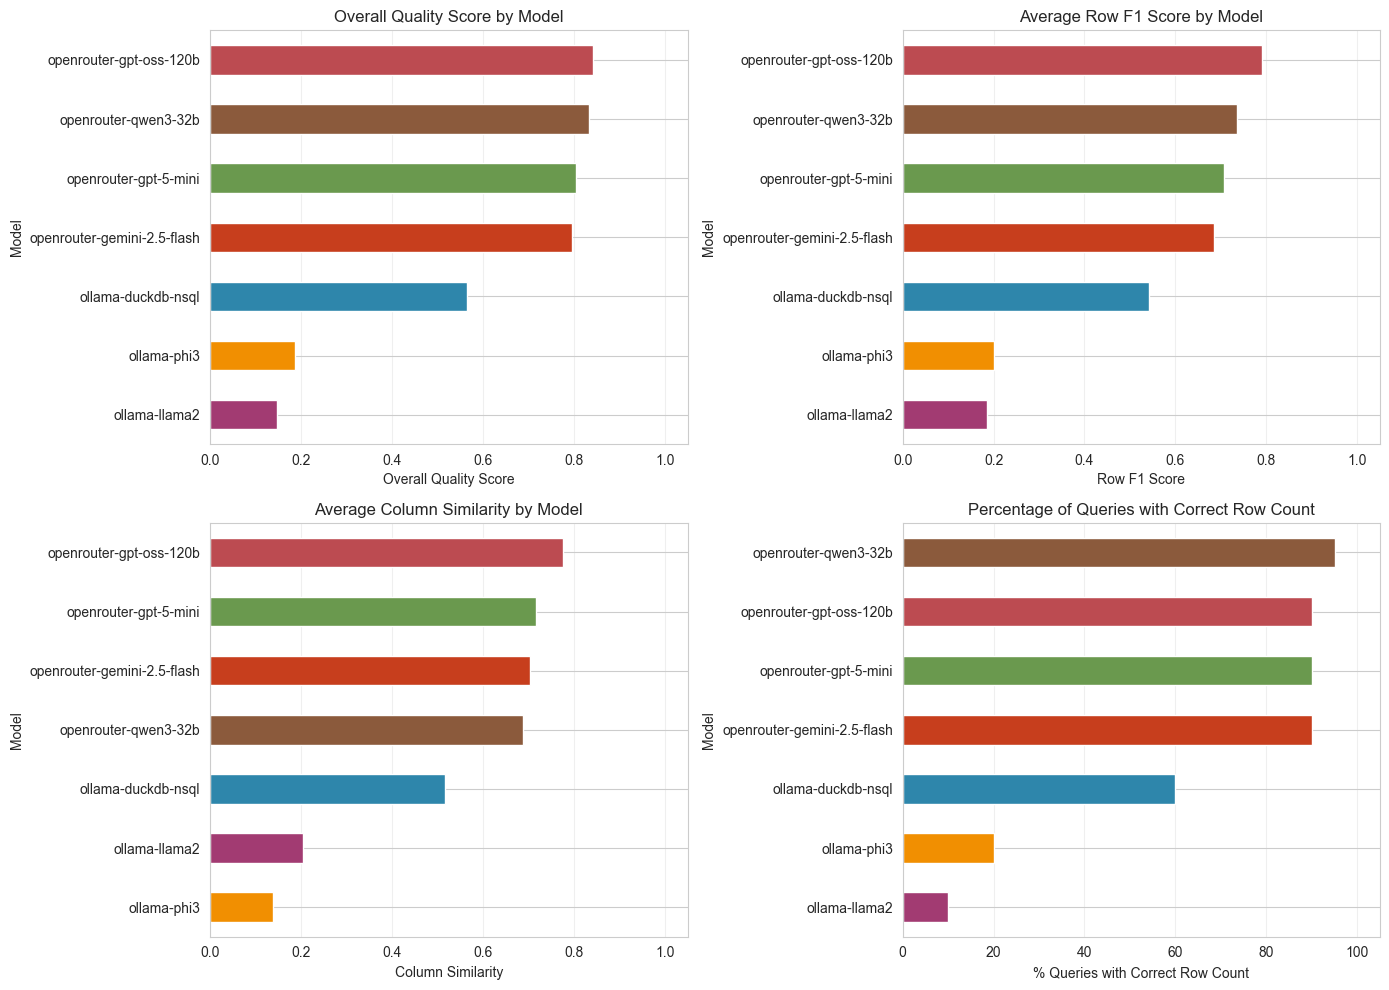

✓ Saved quality metrics overview


In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall score
overall_data = eval_df.groupby('model')['overall_score'].mean().sort_values(ascending=True)
colors_overall = [MODEL_COLORS[m] for m in overall_data.index]
overall_data.plot(kind='barh', ax=axes[0, 0], color=colors_overall)
axes[0, 0].set_xlabel('Overall Quality Score')
axes[0, 0].set_ylabel('Model')
axes[0, 0].set_title('Overall Quality Score by Model')
axes[0, 0].set_xlim(0, 1.05)
axes[0, 0].grid(axis='x', alpha=0.3)

# Row F1
f1_data = eval_df.groupby('model')['row_f1'].mean().sort_values(ascending=True)
colors_f1 = [MODEL_COLORS[m] for m in f1_data.index]
f1_data.plot(kind='barh', ax=axes[0, 1], color=colors_f1)
axes[0, 1].set_xlabel('Row F1 Score')
axes[0, 1].set_ylabel('Model')
axes[0, 1].set_title('Average Row F1 Score by Model')
axes[0, 1].set_xlim(0, 1.05)
axes[0, 1].grid(axis='x', alpha=0.3)

# Column similarity
col_data = eval_df.groupby('model')['column_score'].mean().sort_values(ascending=True)
colors_col = [MODEL_COLORS[m] for m in col_data.index]
col_data.plot(kind='barh', ax=axes[1, 0], color=colors_col)
axes[1, 0].set_xlabel('Column Similarity')
axes[1, 0].set_ylabel('Model')
axes[1, 0].set_title('Average Column Similarity by Model')
axes[1, 0].set_xlim(0, 1.05)
axes[1, 0].grid(axis='x', alpha=0.3)

# % Correct row count
rowcount_data = eval_df.groupby('model')['row_count_score'].apply(
    lambda x: (x == 1.0).sum() / len(x) * 100
).sort_values(ascending=True)
colors_rc = [MODEL_COLORS[m] for m in rowcount_data.index]
rowcount_data.plot(kind='barh', ax=axes[1, 1], color=colors_rc)
axes[1, 1].set_xlabel('% Queries with Correct Row Count')
axes[1, 1].set_ylabel('Model')
axes[1, 1].set_title('Percentage of Queries with Correct Row Count')
axes[1, 1].set_xlim(0, 105)
axes[1, 1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'quality_metrics_overview.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved quality metrics overview")

## 6. Quality by Complexity

In [34]:
# Statistics by complexity
complexity_quality = eval_df.groupby(['model', 'complexity']).agg({
    'overall_score': 'mean',
    'row_f1': 'mean',
    'column_score': 'mean',
    'row_count_score': 'mean'
}).round(4)

complexity_quality.to_csv(TABLES_PATH / 'quality_by_complexity.csv')
print("✓ Saved complexity quality table")

complexity_quality

✓ Saved complexity quality table


overall_score  row_f1  column_score  \
model                       complexity                                        
ollama-duckdb-nsql          complex            0.3804  0.2601        0.4405   
                            moderate           0.4625  0.5000        0.3125   
                            simple             0.9900  1.0000        0.9500   
ollama-llama2               complex            0.0000  0.0000        0.0000   
                            moderate           0.1170  0.2164        0.2604   
                            simple             0.4000  0.4000        0.4000   
ollama-phi3                 complex            0.0000  0.0000        0.0000   
                            moderate           0.2275  0.2500        0.1375   
                            simple             0.3867  0.4000        0.3333   
openrouter-gemini-2.5-flash complex            0.6845  0.4356        0.6262   
                            moderate           0.7663  0.7071        0.5833   
                            simple             1.0000  1.0000        1.0000   
openrouter-gpt-5-mini       complex            0.6191  0.4527        0.6310   
                            moderate           0.8633  0.7450        0.6989   
                            simple             0.9733  1.0000        0.8667   
openrouter-gpt-oss-120b     complex            0.6579  0.5946        0.6119   
                            moderate           0.9060  0.8325        0.7812   
                            simple             1.0000  1.0000        1.0000   
openrouter-qwen3-32b        complex            0.7334  0.5384        0.7167   
                            moderate           0.8510  0.7450        0.6375   
                            simple             0.9467  1.0000        0.7333   

                                        row_count_score  
model                       complexity                   
ollama-duckdb-nsql          complex              0.4286  
                            moderate             0.5000  
                            simple               1.0000  
ollama-llama2               complex              0.0000  
                            moderate             0.0000  
                            simple               0.4000  
ollama-phi3                 complex              0.0000  
                            moderate             0.2500  
                            simple               0.4000  
openrouter-gemini-2.5-flash complex              0.8571  
                            moderate             0.8750  
                            simple               1.0000  
openrouter-gpt-5-mini       complex              0.7143  
                            moderate             1.0000  
                            simple               1.0000  
openrouter-gpt-oss-120b     complex              0.7143  
                            moderate             1.0000  
                            simple               1.0000  
openrouter-qwen3-32b        complex              0.8571  
                            moderate             1.0000  
                            simple               1.0000

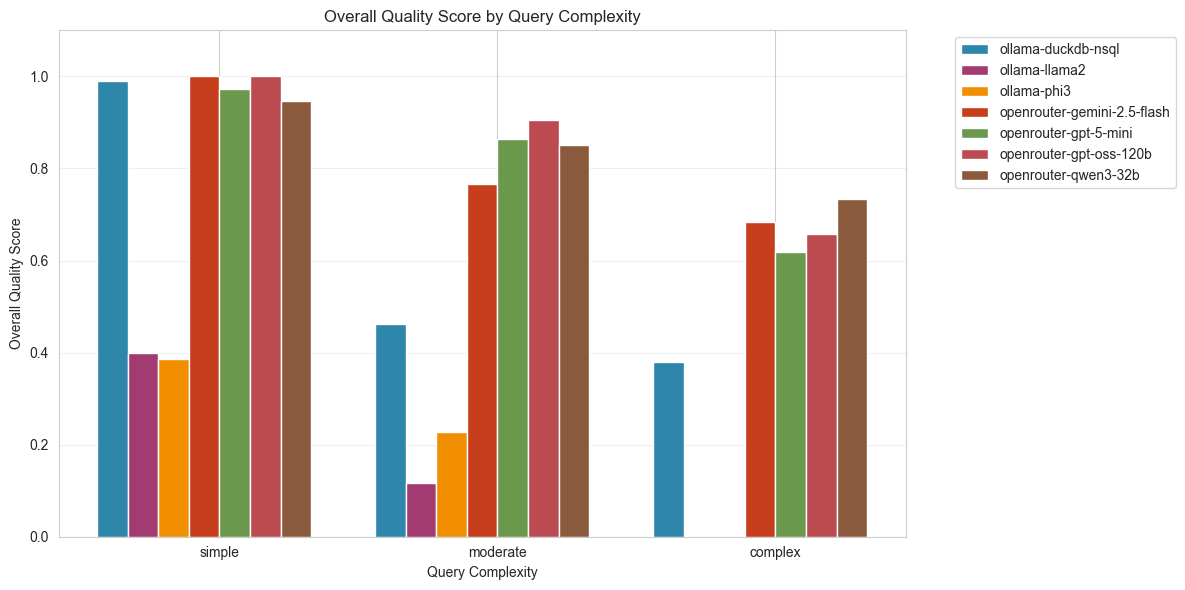

✓ Saved quality by complexity visualization


In [35]:
# Visualize overall score by complexity
complexity_order = ['simple', 'moderate', 'complex']
pivot_data = eval_df.pivot_table(
    values='overall_score',
    index='complexity',
    columns='model',
    aggfunc='mean'
)

pivot_data = pivot_data.reindex(complexity_order)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(complexity_order))
width = 0.11

for i, model in enumerate(models):
    offset = (i - len(models)/2) * width
    values = pivot_data[model].values
    ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])

ax.set_xlabel('Query Complexity')
ax.set_ylabel('Overall Quality Score')
ax.set_title('Overall Quality Score by Query Complexity')
ax.set_xticks(x)
ax.set_xticklabels(complexity_order)
ax.set_ylim(0, 1.1)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'quality_by_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved quality by complexity visualization")

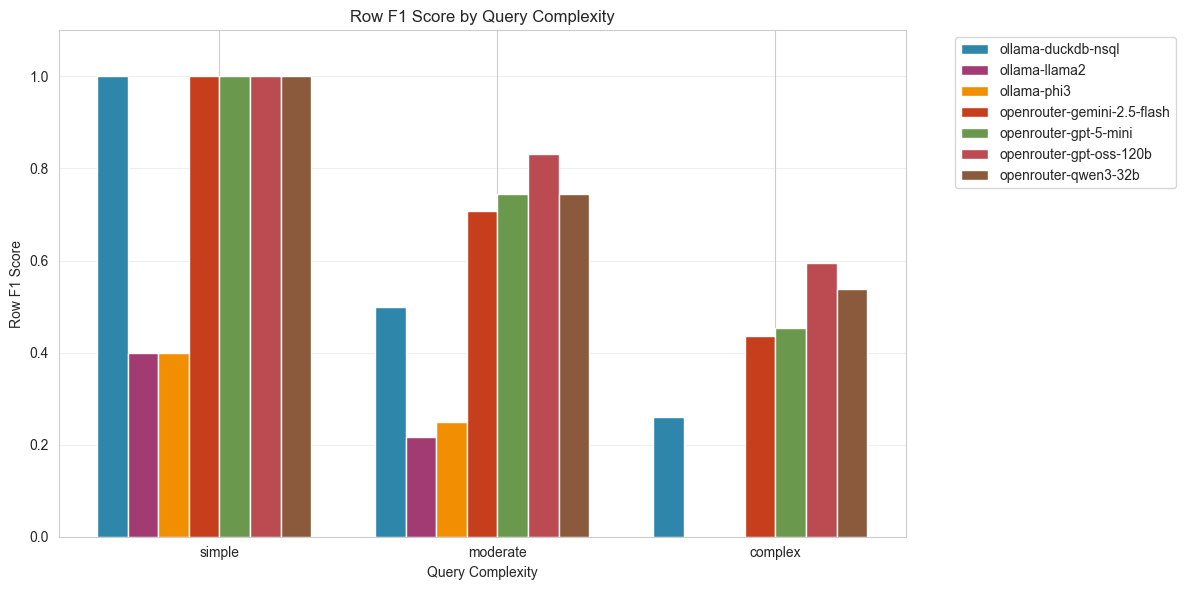

✓ Saved F1 by complexity visualization


In [36]:
# Visualize F1 score by complexity
pivot_f1 = eval_df.pivot_table(
    values='row_f1',
    index='complexity',
    columns='model',
    aggfunc='mean'
)

pivot_f1 = pivot_f1.reindex(complexity_order)

fig, ax = plt.subplots(figsize=(12, 6))

for i, model in enumerate(models):
    offset = (i - len(models)/2) * width
    values = pivot_f1[model].values
    ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])

ax.set_xlabel('Query Complexity')
ax.set_ylabel('Row F1 Score')
ax.set_title('Row F1 Score by Query Complexity')
ax.set_xticks(x)
ax.set_xticklabels(complexity_order)
ax.set_ylim(0, 1.1)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'f1_by_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved F1 by complexity visualization")

## 7. Detailed Analysis: Where Models Fail

In [37]:
# Identify queries where models struggle
struggle_analysis = eval_df.groupby('questionId').agg({
    'overall_score': ['mean', 'std', 'min', 'max'],
    'row_count_score': 'mean'
}).round(4)

struggle_analysis.columns = ['_'.join(col).strip() for col in struggle_analysis.columns.values]
struggle_analysis = struggle_analysis.sort_values('overall_score_mean')

print("\n=== Top 5 Most Challenging Queries ===")
print(struggle_analysis.head())

print("\n=== Top 5 Easiest Queries ===")
print(struggle_analysis.tail())

struggle_analysis.to_csv(TABLES_PATH / 'query_difficulty_analysis.csv')
print("\n✓ Saved query difficulty analysis")


=== Top 5 Most Challenging Queries ===
            overall_score_mean  overall_score_std  overall_score_min  \
questionId                                                             
16                      0.2286             0.2956                0.0   
20                      0.2756             0.2578                0.0   
18                      0.3257             0.3047                0.0   
13                      0.3429             0.3207                0.0   
19                      0.4024             0.3563                0.0   

            overall_score_max  row_count_score_mean  
questionId                                           
16                     0.6500                0.2857  
20                     0.4824                0.0000  
18                     0.5800                0.5714  
13                     0.6000                0.5714  
19                     0.6887                0.5714  

=== Top 5 Easiest Queries ===
            overall_score_mean  overall_score_

In [38]:
# Analyze failure patterns
print("\n=== Common Failure Patterns ===")

# Count different types of failures
failure_counts = eval_df[eval_df['overall_score'] < 1.0].groupby('model')['notes'].apply(
    lambda notes: pd.Series([note for note_list in notes for note in note_list]).value_counts()
)

print(failure_counts.head(20))


=== Common Failure Patterns ===
model                                                 
ollama-duckdb-nsql  Execution failed                       5
                    Column mismatch (similarity: 0.75)     3
                    Column mismatch (similarity: 0.00)     2
                    rowCount differs (0 vs 6)              1
                    Column mismatch (similarity: 0.50)     1
                    Column mismatch (similarity: 0.25)     1
                    rowCount differs (40000 vs 1)          1
                    rowCount differs (2 vs 150)            1
                    Column mismatch (similarity: 0.33)     1
ollama-llama2       Execution failed                      15
                    rowCount differs (21551 vs 10)         1
                    Column mismatch (similarity: 0.75)     1
                    rowCount differs (470 vs 534)          1
                    rowCount differs (427 vs 281)          1
                    Column mismatch (similarity: 0.33)    

## 8. Heatmap: Model Performance per Query

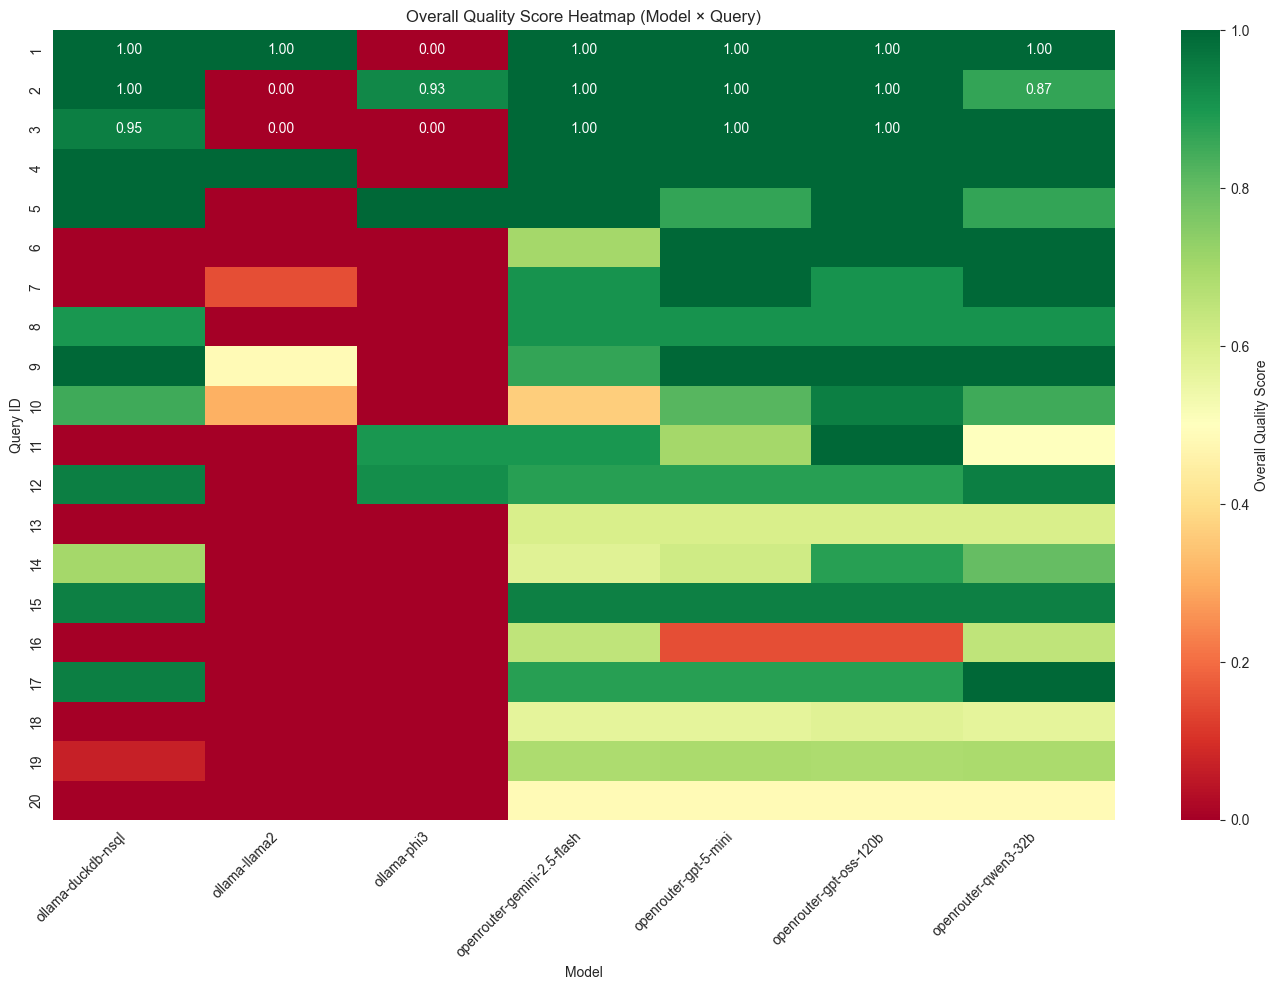

✓ Saved quality heatmap


In [39]:
# Create heatmap of overall scores
heatmap_data = eval_df.pivot_table(
    values='overall_score',
    index='questionId',
    columns='model'
)

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=0,
    vmax=1,
    ax=ax,
    cbar_kws={'label': 'Overall Quality Score'}
)
ax.set_xlabel('Model')
ax.set_ylabel('Query ID')
ax.set_title('Overall Quality Score Heatmap (Model × Query)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIGS_PATH / 'quality_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved quality heatmap")

## 9. Key Findings

### Overall Quality
- Models show significant variation in result quality
- Row count accuracy is often high, but content accuracy varies
- Complex queries show the biggest quality differences

### Common Failure Patterns
- **Near misses**: Models get row count correct but have low F1 (wrong data)
- **Complete failures**: Both row count and columns differ significantly
- **Column aliasing**: Models use different column names but correct data

### Complexity Impact
- Simple queries: Most models achieve >90% quality
- Moderate queries: Quality drops to 70-85% for most models
- Complex queries: Significant variation, some models below 50%

### Model-Specific Observations
- OpenRouter models generally achieve higher F1 scores
- Ollama models are faster but sometimes less accurate on complex queries
- Column similarity is generally high (>0.9) across all models

## 10. Export Summary

In [40]:
# Export detailed results
eval_df.to_csv(TABLES_PATH / 'detailed_quality_results.csv', index=False)
print("✓ Saved detailed quality results")

print("\n" + "="*60)
print("RESULT QUALITY ANALYSIS COMPLETE")
print("="*60)
print(f"Figures saved to: {FIGS_PATH}")
print(f"Tables saved to: {TABLES_PATH}")

✓ Saved detailed quality results

RESULT QUALITY ANALYSIS COMPLETE
Figures saved to: ..\..\analysis\figs
Tables saved to: ..\..\analysis\tables
